In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
import tensorflow as tf

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

In [3]:
MAX_INTENSITY = 255.0
x_train_full = x_train_full.astype("float32") / MAX_INTENSITY
x_test = x_test.astype("float32") / MAX_INTENSITY

N_TRAIN = 50_000
x_val, y_val = x_train_full[N_TRAIN:], y_train_full[N_TRAIN:]
x_train, y_train = x_train_full[:N_TRAIN], y_train_full[:N_TRAIN]

In [4]:
CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", 
               "Dress", "Coat", "Sandal", "Shirt", 
               "Sneaker", "Bag", "Ankle boot"]


In [5]:
print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}, class: {len(CLASS_NAMES)}")

train: (50000, 28, 28), val: (10000, 28, 28), test: (10000, 28, 28), class: 10


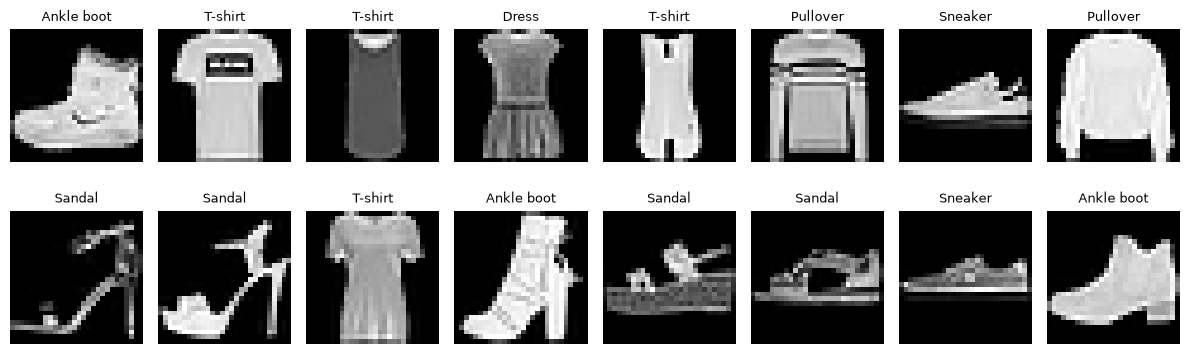

In [6]:
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for ax, img, label in zip(axes.flat, x_train, y_train):
    ax.imshow(img, cmap="gray")
    ax.set_title(CLASS_NAMES[label], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Early stopping

In [7]:
model = keras.Sequential([
    keras.layers.Input(shape=(28,28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])


model_1 = keras.Sequential([
    keras.layers.Input(shape=(28,28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_1.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

In [14]:
result = model.fit(x_train, y_train, validation_split=0.2, epochs=1000, batch_size=200)

Epoch 1/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9980 - loss: 0.0102 - val_accuracy: 0.8977 - val_loss: 0.7285
Epoch 2/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9988 - loss: 0.0074 - val_accuracy: 0.8977 - val_loss: 0.7351
Epoch 3/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9988 - loss: 0.0074 - val_accuracy: 0.8957 - val_loss: 0.7410
Epoch 4/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9986 - loss: 0.0071 - val_accuracy: 0.8963 - val_loss: 0.7381
Epoch 5/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9985 - loss: 0.0073 - val_accuracy: 0.8961 - val_loss: 0.7426
Epoch 6/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9986 - loss: 0.0073 - val_accuracy: 0.8971 - val_loss: 0.7432
Epoch 7/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9985 - loss: 0.0073 - val_accuracy: 0.8979 - val_loss: 0.7400
Epoch 8/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9986 - loss: 0.0068 - 

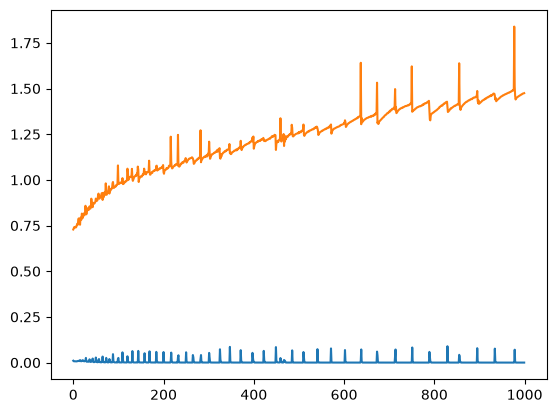

In [15]:
plt.plot(result.history["loss"], label="train loss")
plt.plot(result.history["val_loss"], label="validation loss")
plt.show()

In [18]:
early_stop1 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
result_1 = model.fit(x_train, y_train, validation_split=0.2, epochs=1000, batch_size=200, callbacks=[early_stop1])

Epoch 1/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 2.4040e-05 - val_accuracy: 0.8966 - val_loss: 1.4768
Epoch 2/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 2.3115e-05 - val_accuracy: 0.8969 - val_loss: 1.4773
Epoch 3/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 2.2325e-05 - val_accuracy: 0.8971 - val_loss: 1.4783
Epoch 4/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 2.1819e-05 - val_accuracy: 0.8968 - val_loss: 1.4803
Epoch 5/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 2.1074e-05 - val_accuracy: 0.8971 - val_loss: 1.4807
Epoch 6/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 2.0493e-05 - val_accuracy: 0.8973 - val_loss: 1.4809
Epoch 7/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 1.9855e-05 - val_accuracy: 0.8960 - val_loss: 1.4840
Epoch 8/1000
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accura

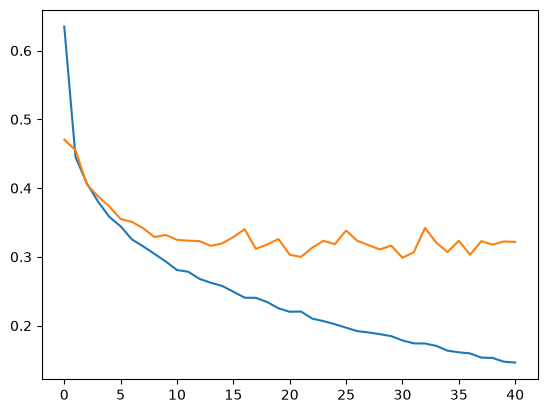

In [17]:
plt.plot(result_1.history["loss"], label="train loss model_1")
plt.plot(result_1.history["val_loss"], label="validation loss model_1")
plt.show()